# 02 · Setup_folds_and_dataloader_explained

This notebook prepares everything a model needs **before** training:

| Part | What |
|---|---|
| 0 | Setup |
| 1 | Why cross-validation, and why **by session** |
| 2 | The folds we made |
| 3 | What a `Dataset` and a `DataLoader` are |
| 4 | Step 1: the cache (fast loading) |
| 5 | Step 2: preprocessing options |
| 6 | Step 3: the `Dataset` (one example at a time) |
| 7 | Step 4: the `DataLoader` (batches) and class balance |
| 8 | Summary: how training will use all this |

The sessions and folds were written to the database by `uv run python -m ureca.dataset.folds`. This notebook only reads them.

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from torch.utils.data import DataLoader

from ureca.dataset.loading import CLASSES, FS, TRIGGER, load_index, load_waveforms, fold_split
from ureca.dataset.torch_data import preprocess, WaveformDataset, class_weights, balanced_sampler
from ureca.dataset.folds import N_FOLDS, SESSION_GAP_S
from ureca.plotting import set_style, NAMES, COLORS, FOLD_COLORS, INK, INK2, SURFACE

set_style()
files = load_index()
files.head()

,file_id,raw_path,label,timestamp,sha256,session_id,fold,y,ts
0,1,partial_discharge/PA20260901105717.txt,partial_discharge,2026-09-01T10:57:17,e5f8c2ab2f817af1991b02584f0ee3a51745aba6dad7a2...,partial_discharge@2026-09-01T10:57:17,0,0,2026-09-01 10:57:17
1,2,partial_discharge/PA20260901113802.txt,partial_discharge,2026-09-01T11:38:02,084b637923103d564c2bb6a9d3437652ca7222e8c86085...,partial_discharge@2026-09-01T11:38:02,1,0,2026-09-01 11:38:02
2,3,partial_discharge/PA20260901154521.txt,partial_discharge,2026-09-01T15:45:21,34f31fb2c0a082e14f3058dddfd7927e7ec44084966c1b...,partial_discharge@2026-09-01T15:45:21,0,0,2026-09-01 15:45:21
3,4,partial_discharge/PA20260901155559.txt,partial_discharge,2026-09-01T15:55:59,777ed4dcff817373d984409a0ad59194327cdc1b0c075d...,partial_discharge@2026-09-01T15:55:59,1,0,2026-09-01 15:55:59
4,5,partial_discharge/PA20260902100616.txt,partial_discharge,2026-09-02T10:06:16,e26be758129291ccb7b6803453ed8085020cd85983fc92...,partial_discharge@2026-09-02T10:06:16,1,0,2026-09-02 10:06:16


## 1. Why cross-validation, and why by session?

**The problem.** A model is judged on files it did **not** learn from. Normally you set some files aside as a fixed *test set*. With only 7 transient-noise and 8 spark-lighter files, a 20% test set would hold 1–2 files of those classes, and one lucky or unlucky file would swing the score enormously.

**Cross-validation (CV)** fixes this by *rotating*. The data is cut into **3 folds**. We train 3 times; each time one fold is held out for validation and the other two are used for training. In the end **every file has been validated exactly once**, and we report the average over the 3 rounds.

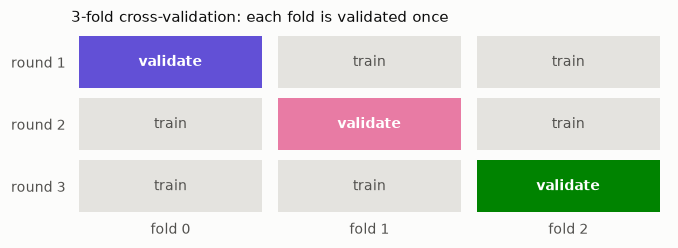

In [2]:
fig, ax = plt.subplots(figsize=(7, 2.2))
for r in range(N_FOLDS):
    for k in range(N_FOLDS):
        val = r == k
        ax.add_patch(plt.Rectangle((k + 0.04, N_FOLDS - 1 - r + 0.08), 0.92, 0.84,
                                   color=FOLD_COLORS[k] if val else "#e4e3df", linewidth=0))
        ax.text(k + 0.5, N_FOLDS - 0.5 - r, "validate" if val else "train", ha="center", va="center",
                color="white" if val else INK2, fontsize=9, fontweight="bold" if val else "normal")
ax.set_xlim(0, N_FOLDS); ax.set_ylim(0, N_FOLDS)
ax.set_xticks(np.arange(N_FOLDS) + 0.5, [f"fold {k}" for k in range(N_FOLDS)])
ax.set_yticks(np.arange(N_FOLDS) + 0.5, [f"round {r + 1}" for r in range(N_FOLDS)][::-1])
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("3-fold cross-validation: each fold is validated once", loc="left")
plt.show()

**Why by session, not by file?** The EDA found that files recorded seconds apart are near-copies (switching noise was captured once per second for a minute). If those copies are split between training and validation, the model is tested on files it has effectively already seen, and the score looks better than it really is (*data leakage*).

So we first group files into **recording sessions**: files of the same class recorded less than 60 s apart belong together. Then **whole sessions** are assigned to folds. A session is never split.

## 2. The folds we made

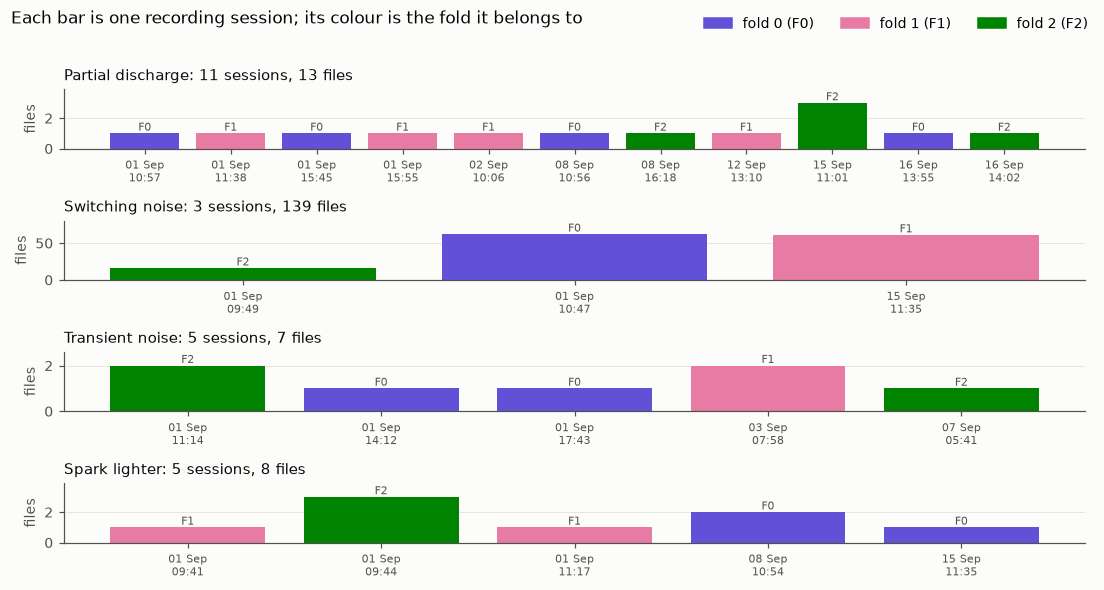

In [3]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(10, 5.2), sharex=False)
for ax, c in zip(axes, CLASSES):
    s = (files[files["label"] == c].groupby("session_id")
         .agg(n=("file_id", "size"), fold=("fold", "first"), start=("ts", "min")).sort_values("start"))
    x = np.arange(len(s))
    ax.bar(x, s["n"], color=[FOLD_COLORS[f] for f in s["fold"]], width=0.8)
    for xi, (n, f) in enumerate(zip(s["n"], s["fold"])):
        ax.text(xi, n, f"F{f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
    ax.set_xticks(x, s["start"].dt.strftime("%d %b\n%H:%M"), fontsize=7)
    ax.set_title(f"{NAMES[c]}: {len(s)} sessions, {s['n'].sum()} files", loc="left")
    ax.set_ylabel("files"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, s["n"].max() * 1.3)
fig.legend(handles=[Patch(color=FOLD_COLORS[k], label=f"fold {k} (F{k})") for k in range(N_FOLDS)],
           loc="upper right", ncol=3, bbox_to_anchor=(1, 1.03))
fig.suptitle("Each bar is one recording session; its colour is the fold it belongs to", x=0.01, ha="left", y=1.02)
plt.tight_layout(); plt.show()

In [4]:
table = pd.crosstab(files["label"].map(NAMES), files["fold"].map(lambda f: f"fold {f}"))
table["total"] = table.sum(axis=1)
table.loc["total"] = table.sum()
table

fold,fold 0,fold 1,fold 2,total
label,,,,
Partial discharge,4,4,5,13
Spark lighter,3,2,3,8
Switching noise,62,61,16,139
Transient noise,2,2,3,7
total,71,69,27,167


**Explanation:**
- There are **24 sessions** in total. Partial discharge has many small sessions (good: lots of variety). Switching noise has only **3 sessions**, but they are huge (16, 61 and 62 files).
- That is why we use **3 folds**: with 3 switching-noise sessions, each fold gets exactly one. More folds would leave some folds with no switching noise to validate.
- Sessions were given to folds largest-first, always to the fold with the fewest files of that class, so **every fold contains every class**.
- Fold sizes are uneven (fold 2 has only 27 files) because switching noise cannot be split more finely. That is the price of an honest split.

**New data:** `ingest` now runs this assignment automatically after each batch. Existing sessions keep their fold, and new sessions go to the emptiest fold for their class, so earlier results stay comparable.

## 3. What are a `Dataset` and a `DataLoader`?

A neural network does not read files. It needs **numbers in a fixed shape**, delivered in small groups called **batches**. PyTorch splits this job into two pieces:

| Piece | Job | Analogy |
|---|---|---|
| **`Dataset`** | Knows how to fetch **one** example: "give me example *i*" → `(waveform tensor, label)` | A librarian who can fetch any single book by its number |
| **`DataLoader`** | Asks the Dataset for many examples, **shuffles** them, and stacks them into **batches** | A trolley that collects 32 books at a time in random order |

Our pipeline, from database to model:

```
database row ──► waveform array ──► preprocess ──► tensor [1, L] ──► batch [32, 1, L] ──► CNN
  (load_index)   (load_waveforms,   (crop,          (WaveformDataset)  (DataLoader)
                  cached)            normalise)
```

The code lives in `src/ureca/dataset/loading.py` (loading) and `src/ureca/dataset/torch_data.py` (preprocessing, PyTorch), so every notebook and training script loads data in exactly the same way. The next parts go through each step.

## 4. Step 1: the cache

The raw files are text, one number per line. Reading text is slow. The first time, `load_waveforms` reads them all and saves one binary file `cache/waveforms.npz` in the data root. After that it loads from the cache. Each waveform is stored under its **sha256 hash**, so a new file is simply added and nothing goes stale.

In [5]:
t0 = time.perf_counter(); X = load_waveforms(files); t_cache = time.perf_counter() - t0

from ureca.config import ensure_dirs
proc = ensure_dirs()["processed"]
t0 = time.perf_counter(); _ = [np.loadtxt(proc / p) for p in files["raw_path"]]; t_text = time.perf_counter() - t0

print(f"array shape: {X.shape}, dtype {X.dtype}, {X.nbytes / 1e6:.1f} MB")
print(f"from text : {t_text:.2f} s\nfrom cache: {t_cache:.3f} s  ({t_text / t_cache:.0f}x faster)")

167 waveforms: 167 from cache, 0 read from text


array shape: (167, 16384), dtype float32, 10.9 MB
from text : 0.53 s
from cache: 0.019 s  (27x faster)


**Explanation:** all 167 waveforms fit in one array of shape `(167, 16384)`: 167 files × 16,384 samples. The cache makes loading many times faster. That matters later, when training runs many times (3 folds × several experiments). `float32` is used because it is what neural networks work with, and it halves the memory.

## 5. Step 2: preprocessing options

Before the waveform goes to the model, `preprocess()` can change it. These are **choices to experiment with**, not fixed rules:

| Option | What it does | Why |
|---|---|---|
| baseline removal (always) | subtract the median | removes the few-mV DC offset |
| `crop=(-10, 50)` | keep −10 µs … +50 µs around the trigger (7,500 samples) | the event is at the trigger; a smaller input is faster to train on |
| `normalize="global"` | divide every file by one fixed number | puts values on a similar scale but **keeps** amplitude differences |
| `normalize="peak"` | divide each file by its own peak | removes amplitude completely; the model must use **shape only** |

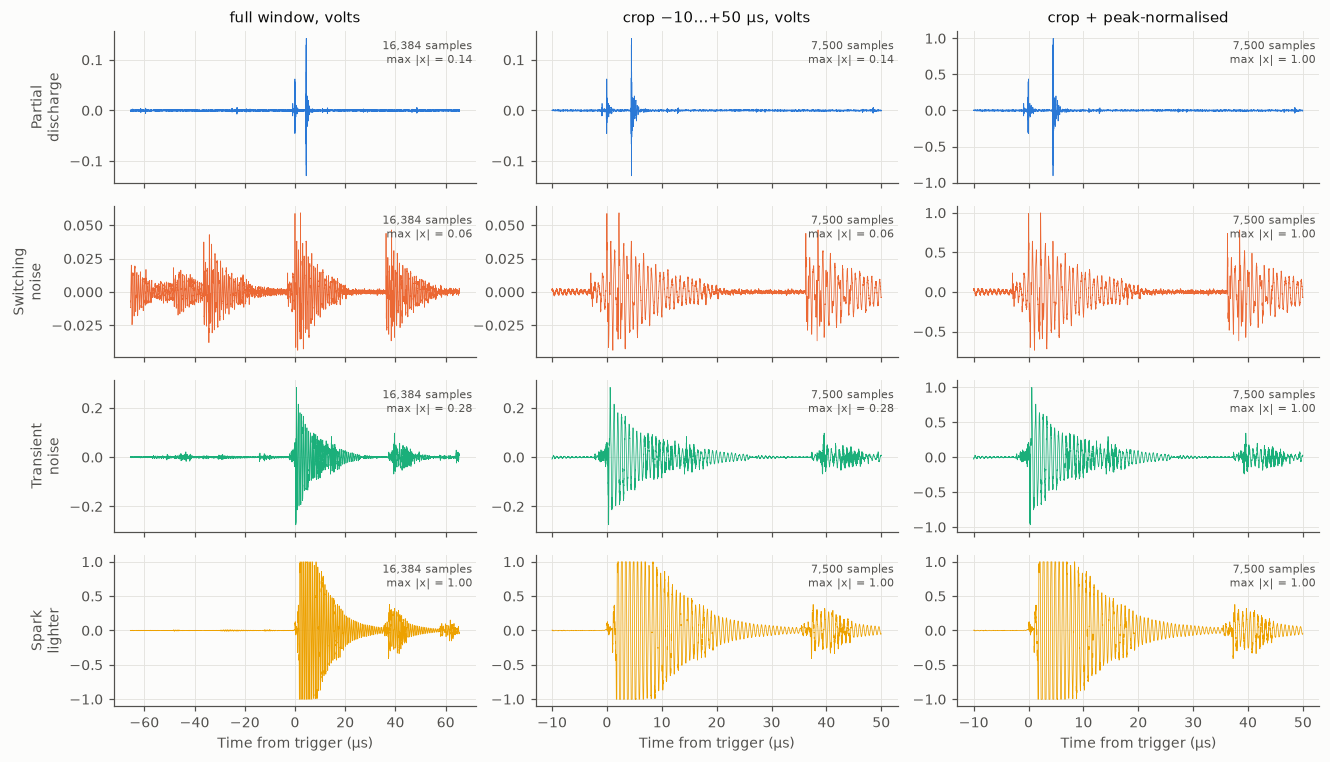

In [6]:
examples = [files.index[files["label"] == c][0] for c in CLASSES]
settings = [("full window, volts", dict()),
            ("crop −10…+50 µs, volts", dict(crop=(-10, 50))),
            ("crop + peak-normalised", dict(crop=(-10, 50), normalize="peak"))]

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 7), sharex="col")
for r, (c, i) in enumerate(zip(CLASSES, examples)):
    for k, (title, kw) in enumerate(settings):
        x = preprocess(X[i], **kw)
        start = kw.get("crop", (-TRIGGER / FS * 1e6, None))[0]
        t = start + np.arange(len(x)) / FS * 1e6
        ax = axes[r, k]
        ax.plot(t, x, color=COLORS[c], linewidth=0.5)
        if r == 0: ax.set_title(title)
        if k == 0: ax.set_ylabel(NAMES[c].replace(" ", "\n"))
        ax.text(0.99, 0.95, f"{len(x):,} samples\nmax |x| = {np.abs(x).max():.2f}", transform=ax.transAxes,
                ha="right", va="top", fontsize=7.5, color=INK2)
for ax in axes[-1]: ax.set_xlabel("Time from trigger (µs)")
plt.tight_layout(); plt.show()

**Explanation:**
- **Cropping** keeps the event and its ringing, and cuts the input from 16,384 to 7,500 samples.
- In volts (middle column) the spark lighter is ~15× larger than PD. After **peak normalisation** (right column) every waveform goes from −1 to +1, so the model can only use the **shape**. That guards against the hardware clues found in the EDA (the trigger level and clipping).
- Which option works best is an experiment for the CNN stage. The baseline in notebook 03 already hints at how much the model relies on amplitude.

⚠️ For `normalize="global"`, the scale must be computed from the **training folds only**. Using the validation files to choose it would be a small leak.

## 6. Step 3: the `Dataset`

`WaveformDataset` takes the big array, the labels, **which rows to use** (for example the training rows of round 1) and the preprocessing options. Asking it for item `i` returns a tensor and the class id.

In [7]:
train_rows, val_rows = fold_split(files, k=0)
train_ds = WaveformDataset(X, files["y"], train_rows, crop=(-10, 50), normalize="peak")
val_ds   = WaveformDataset(X, files["y"], val_rows,   crop=(-10, 50), normalize="peak")

x, y = train_ds[0]
print(f"Round 1 (fold 0 held out): {len(train_ds)} training files, {len(val_ds)} validation files")
print(f"one item -> x: {tuple(x.shape)} {x.dtype},  y: {y} ({CLASSES[y]})")
print("class ids:", {i: c for i, c in enumerate(CLASSES)})

Round 1 (fold 0 held out): 96 training files, 71 validation files
one item -> x: (1, 7500) torch.float32,  y: 0 (partial_discharge)
class ids: {0: 'partial_discharge', 1: 'switching_noise', 2: 'transient_noise', 3: 'spark_lighter'}


**Explanation:** each item is a tensor of shape **`[1, 7500]`**:
- `1` is the number of *channels*. We have one sensor. It works like a greyscale image having 1 colour channel. 1-D CNN layers expect this dimension.
- `7500` is the number of time samples after cropping.

The label is a number (0–3), because models output numbers. The list `CLASSES` translates it back to a name. The two datasets use the same array; they just use different rows, so no data is copied.

## 7. Step 4: the `DataLoader` and class balance

The `DataLoader` groups items into batches, e.g. 32 at a time. A batch has shape `[32, 1, 7500]`. The CNN processes a whole batch at once and updates its weights once per batch. One pass over all training files is called an **epoch**.

**The imbalance problem:** if batches are drawn by plain shuffling, most of every batch is switching noise and the model rarely sees the other classes. There are two standard fixes, and we have helpers for both:
1. **Balanced sampler** (`balanced_sampler`): draws rare-class files more often, so batches are roughly balanced.
2. **Class weights** (`class_weights`): a mistake on a rare class costs more in the loss.

Usually you pick **one** of the two. Using both over-corrects.

one batch -> x: (32, 1, 7500)  y: (32,)


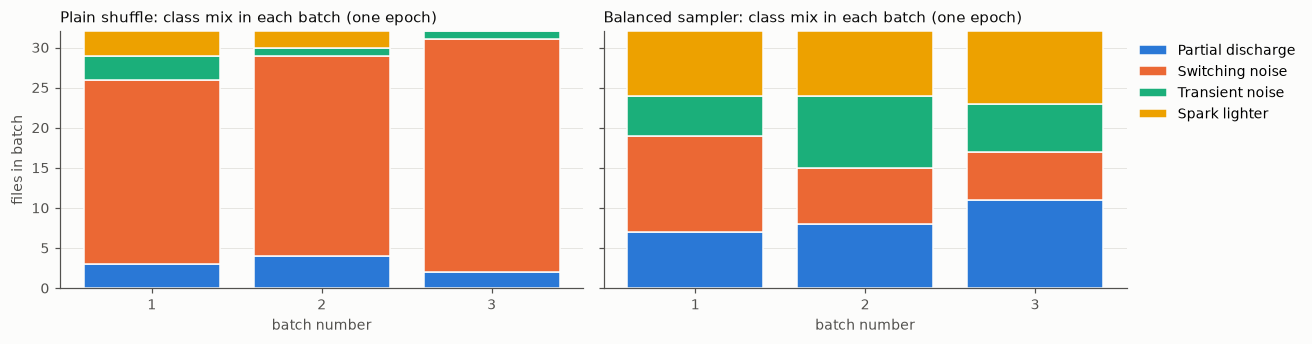

In [8]:
y_train = files["y"].values[train_rows]
loaders = {
    "Plain shuffle": DataLoader(train_ds, batch_size=32, shuffle=True),
    "Balanced sampler": DataLoader(train_ds, batch_size=32, sampler=balanced_sampler(y_train)),
}
xb, yb = next(iter(loaders["Plain shuffle"]))
print("one batch -> x:", tuple(xb.shape), " y:", tuple(yb.shape))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (name, dl) in zip(axes, loaders.items()):
    counts = np.array([np.bincount(yb.numpy(), minlength=4) for _, yb in dl])
    bottom = np.zeros(len(counts))
    for j, c in enumerate(CLASSES):
        ax.bar(np.arange(len(counts)), counts[:, j], bottom=bottom, color=COLORS[c],
               edgecolor=SURFACE, linewidth=1, width=0.8, label=NAMES[c])
        bottom += counts[:, j]
    ax.set_title(f"{name}: class mix in each batch (one epoch)", loc="left")
    ax.set_xticks(np.arange(len(counts)), np.arange(1, len(counts) + 1))
    ax.set_xlabel("batch number"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("files in batch")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

In [9]:
w = class_weights(y_train)
pd.DataFrame({"training files": np.bincount(y_train, minlength=4), "loss weight": w.numpy().round(2)},
             index=[NAMES[c] for c in CLASSES])

,training files,loss weight
Partial discharge,9,2.67
Switching noise,77,0.31
Transient noise,5,4.80
Spark lighter,5,4.80


**Explanation:**
- **Left (plain shuffle):** nearly every batch is mostly orange (switching noise). Some batches contain no transient noise or spark lighter at all.
- **Right (balanced sampler):** each batch has a similar share of all four classes. Rare-class files are drawn **with replacement**, so the same file can appear several times in an epoch. That is fine, but it makes **data augmentation** (small shifts, added noise) more useful, so the repeats are not identical.
- **Class weights:** with the loss weights in the table, one transient-noise mistake counts about 20× more than one switching-noise mistake.

## 8. Summary: how training will use this

```python
for k in range(3):                                   # one round per fold
    train_rows, val_rows = fold_split(files, k)
    train_dl = DataLoader(WaveformDataset(X, y, train_rows, crop=..., normalize=...),
                          batch_size=32, sampler=balanced_sampler(y[train_rows]))
    val_dl   = DataLoader(WaveformDataset(X, y, val_rows,   crop=..., normalize=...), batch_size=64)
    model = make_cnn()                               # a fresh model every round
    train(model, train_dl)                           # learns from 2 folds
    evaluate(model, val_dl)                          # scored on the unseen fold
# report the mean ± spread over the 3 rounds
```

What is ready:
- ✅ Sessions and folds stored in the database, assigned automatically for new batches
- ✅ Fast cached loading (`load_waveforms`)
- ✅ `WaveformDataset` with crop and normalisation options
- ✅ Balanced sampler and class weights for the imbalance

Next: **notebook 03** trains a simple baseline with the same folds. Its score is the target the CNN must beat.